In [51]:
import pandas as pd
import numpy as np
import torch

from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D 

In [61]:
device = torch.device("cpu")

path = "dataset/Salary_dataset.csv"
df = pd.read_csv(path)

X = torch.tensor(df.iloc[:, 1].values, dtype=torch.float32).unsqueeze(1)#Estudiar unsqueeze
y = torch.tensor(df.iloc[:, 2].values, dtype=torch.float32).unsqueeze(1)

m = X.shape[0]

torch.manual_seed(42)
indices = torch.randperm(m)
X = X[indices]
y = y[indices]

train_size = int(0.8 * m)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Total de muestras (m): {m}")
print(f"X_train shape: {X_train.shape} | Dispositivo: {X_train.device}")
print(f"X_test shape:  {X_test.shape}  | Dispositivo: {X_test.device}")

Total de muestras (m): 30
X_train shape: torch.Size([24, 1]) | Dispositivo: cpu
X_test shape:  torch.Size([6, 1])  | Dispositivo: cpu


In [53]:
print(X)

tensor([[ 4.1000],
        [ 1.2000],
        [ 3.1000],
        [ 9.1000],
        [ 3.3000],
        [ 5.0000],
        [ 4.0000],
        [ 6.0000],
        [ 5.2000],
        [ 8.3000],
        [10.4000],
        [ 9.6000],
        [ 6.9000],
        [ 3.3000],
        [ 7.2000],
        [ 8.0000],
        [10.6000],
        [ 4.2000],
        [ 4.6000],
        [ 1.6000],
        [ 2.3000],
        [ 1.4000],
        [ 3.8000],
        [ 4.1000],
        [ 5.4000],
        [ 6.1000],
        [ 9.7000],
        [ 3.0000],
        [ 8.8000],
        [ 2.1000]])


In [54]:
print(y)

tensor([[ 56958.],
        [ 39344.],
        [ 60151.],
        [105583.],
        [ 64446.],
        [ 67939.],
        [ 63219.],
        [ 81364.],
        [ 66030.],
        [113813.],
        [122392.],
        [116970.],
        [ 91739.],
        [ 54446.],
        [ 98274.],
        [101303.],
        [121873.],
        [ 57082.],
        [ 61112.],
        [ 37732.],
        [ 39892.],
        [ 46206.],
        [ 57190.],
        [ 55795.],
        [ 83089.],
        [ 93941.],
        [112636.],
        [ 56643.],
        [109432.],
        [ 43526.]])


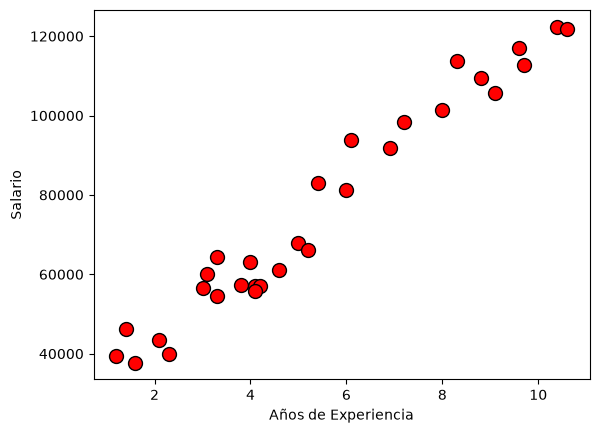

In [ ]:
def plotData(x, y):

    fig = pyplot.figure()

    pyplot.plot(x, y, 'ro', ms=10, mec='k')
    pyplot.ylabel('Salario')
    pyplot.xlabel('Años de Experiencia')

plotData(X,y)

In [56]:
def featureNormalize(X,y):
    
    mu = X.mean(dim=0)
    sigma = X.std(dim=0)

    mu_y = y.mean(dim=0)
    sigma_y = y.std(dim=0)

    X_norm = (X - mu) / sigma
    y_norm = (y - mu_y) / sigma_y

    return X_norm, y_norm, mu, mu_y, sigma, sigma_y


X_train_norm, y_train_norm, mu, mu_y, sigma, sigma_y = featureNormalize(X_train, y_train)

print(X_train_norm)
print(y_train_norm)

tensor([[-0.4233],
        [-1.4426],
        [-0.7748],
        [ 1.3343],
        [-0.7045],
        [-0.1069],
        [-0.4584],
        [ 0.2446],
        [-0.0366],
        [ 1.0531],
        [ 1.7912],
        [ 1.5100],
        [ 0.5609],
        [-0.7045],
        [ 0.6664],
        [ 0.9476],
        [ 1.8615],
        [-0.3881],
        [-0.2475],
        [-1.3020],
        [-1.0560],
        [-1.3723],
        [-0.5287],
        [-0.4233]])
tensor([[-0.6259],
        [-1.2653],
        [-0.5100],
        [ 1.1391],
        [-0.3541],
        [-0.2273],
        [-0.3987],
        [ 0.2600],
        [-0.2966],
        [ 1.4378],
        [ 1.7492],
        [ 1.5524],
        [ 0.6366],
        [-0.7171],
        [ 0.8738],
        [ 0.9837],
        [ 1.7304],
        [-0.6214],
        [-0.4752],
        [-1.3238],
        [-1.2454],
        [-1.0162],
        [-0.6175],
        [-0.6682]])


In [57]:
D_in, D_out = 1, 1

model = torch.nn.Sequential(
    torch.nn.Linear(D_in, D_out)
).to(device)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

epochs = 500
log_each = 50
l = []

model.train()

for e in range(1, epochs + 1):

    # forward
    y_pred = model(X_train_norm)

    # loss
    loss = criterion(y_pred, y_train_norm)
    l.append(loss.item())

    # ponemos a cero los gradientes
    optimizer.zero_grad()

    # Backprop (calculamos todos los gradientes automáticamente)
    loss.backward()

    # update de los pesos
    optimizer.step()

    if not e % log_each:
        print(f"Epoch {e}/{epochs} Loss {np.mean(l):.5f}")

Epoch 50/500 Loss 0.53126
Epoch 100/500 Loss 0.28514
Epoch 150/500 Loss 0.20309
Epoch 200/500 Loss 0.16207
Epoch 250/500 Loss 0.13745
Epoch 300/500 Loss 0.12104
Epoch 350/500 Loss 0.10932
Epoch 400/500 Loss 0.10053
Epoch 450/500 Loss 0.09369
Epoch 500/500 Loss 0.08823


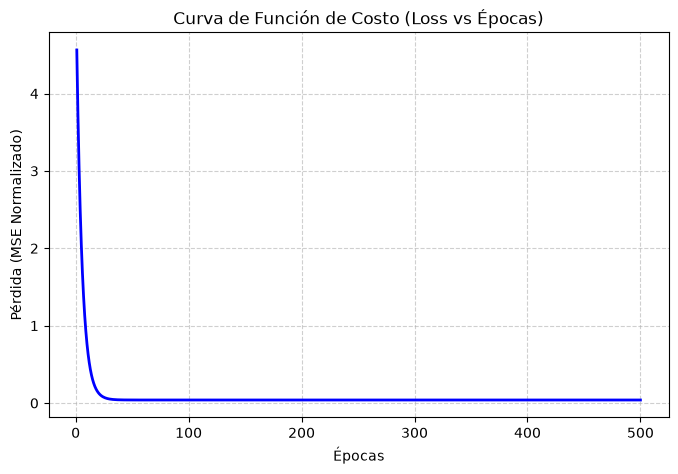

In [58]:
pyplot.figure(figsize=(8, 5))

pyplot.plot(range(1, epochs + 1), l, color='blue', linewidth=2)

pyplot.title('Curva de Función de Costo (Loss vs Épocas)')
pyplot.xlabel('Épocas')
pyplot.ylabel('Pérdida (MSE Normalizado)')
pyplot.grid(True, linestyle='--', alpha=0.6)

pyplot.show()

In [60]:
model.eval()

X_test_norm = (X_test - mu) / sigma
y_test_norm = (y_test - mu_y) / sigma_y

with torch.no_grad():

    y_pred_test = model(X_test_norm)
    
    y_true_mean = torch.mean(y_test_norm)
    
    ss_res = torch.sum((y_test_norm - y_pred_test) ** 2)
    
    ss_tot = torch.sum((y_test_norm - y_true_mean) ** 2)
    
    r2_score = 1 - (ss_res / ss_tot)
    
    porcentaje_acierto = r2_score.item() * 100

print(f"\nPorcentaje de aprendizaje/ajuste: {porcentaje_acierto:.2f}%")


Porcentaje de aprendizaje/ajuste: 93.78%
